In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


In [2]:
eda = pd.read_json(
    r"D:\FPT\ADY291m\project\data\processed\18-10-2026.json",
    dtype={"source_review_id": "string", "shop_id": "string", "user_pseudo_id": "string"},
)
# Giữ bản dữ liệu gốc; mọi phân tích phía sau dùng eda đầy đủ cột.
df_raw = eda.copy(deep=True)
eda.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138131 entries, 0 to 138130
Data columns (total 34 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   review_id          138131 non-null  int64         
 1   source_review_id   124101 non-null  string        
 2   shop_id            138131 non-null  string        
 3   user_pseudo_id     138131 non-null  string        
 4   rating             138131 non-null  float64       
 5   device             138131 non-null  object        
 6   comment_datetime   138131 non-null  object        
 7   comment_text       138131 non-null  object        
 8   num_photos         124101 non-null  float64       
 9   source_platform    138131 non-null  object        
 10  crawled_at         138131 non-null  datetime64[ns]
 11  user_name          138131 non-null  object        
 12  first_seen_at      138131 non-null  datetime64[ns]
 13  shop_name          138131 non-null  object  

### 1. Kiểm tra chất lượng dữ liệu

In [3]:
required_columns = {"rating", "comment_text"}
missing_columns = required_columns - set(eda.columns)

if missing_columns:
    raise ValueError(f"Thiếu các cột: {sorted(missing_columns)}")

# Giữ toàn bộ cột trong eda để còn khảo sát khóa lọc trùng.
eda["rating_num"] = pd.to_numeric(eda["rating"], errors="coerce")

# Giữ comment gốc; tạo bản chuẩn hóa riêng để thống kê
eda["text_norm"] = (
    eda["comment_text"]
    .astype("string")
    .fillna("")
    .str.normalize("NFC")
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

text_missing = eda["comment_text"].isna()
text_empty = eda["text_norm"].eq("")
rating_missing = eda["rating"].isna()
rating_unreadable = (
    eda["rating"].notna() & eda["rating_num"].isna()
)
rating_outside = (
    eda["rating_num"].notna()
    & ~eda["rating_num"].between(0, 10)
)

valid = (
    ~text_empty
    & eda["rating_num"].between(0, 10)
)

audit = pd.Series({
    "Tổng số dòng": len(eda),
    "Comment thiếu": int(text_missing.sum()),
    "Comment rỗng, gồm cả thiếu": int(text_empty.sum()),
    "Rating thiếu": int(rating_missing.sum()),
    "Rating không chuyển được thành số": int(rating_unreadable.sum()),
    "Rating ngoài khoảng 0–10": int(rating_outside.sum()),
    "Dòng có rating = 0": int(eda["rating_num"].eq(0).sum()),
    "Dòng đủ comment và rating hợp lệ": int(valid.sum()),
}, name="Số lượng")

display(audit.to_frame())

# Tập hợp lệ cho audit; chưa lọc comment trùng và vẫn giữ rating 0.
corpus = eda.loc[valid].copy()

if corpus.empty:
    raise ValueError("Không có review đáp ứng điều kiện đầu vào.")

duplicate_text = corpus["text_norm"].duplicated(keep=False)

duplicate_summary = pd.Series({
    "Số nội dung khác nhau": corpus["text_norm"].nunique(),
    "Số dòng thuộc nhóm nội dung lặp": int(duplicate_text.sum()),
    "Số dòng dư nếu chỉ giữ 1 dòng mỗi nội dung":
        int(corpus["text_norm"].duplicated().sum()),
}, name="Số lượng")

display(duplicate_summary.to_frame())

,Số lượng
Tổng số dòng,138131
Comment thiếu,0
"Comment rỗng, gồm cả thiếu",0
Rating thiếu,0
Rating không chuyển được thành số,0
Rating ngoài khoảng 0–10,0
Dòng có rating = 0,40
Dòng đủ comment và rating hợp lệ,138131


,Số lượng
Số nội dung khác nhau,126236
Số dòng thuộc nhóm nội dung lặp,17619
Số dòng dư nếu chỉ giữ 1 dòng mỗi nội dung,11895


#### Có thể thấy dữ liệu đang có chất lượng khá tốt , không có các comment rỗng hay rating thiếu , không hợp lệ . Tuy nhiên , vẫn cần take care đến các rating = 0 (40 reviews) . Các review này có thể bao gồm cả những review tích cực nhưng quên đánh giá 


In [4]:
with pd.option_context("display.max_colwidth", None):
    display(
        eda.loc[eda["rating_num"].eq(0), ["rating", "comment_text"]].head(5)
    )

,rating,comment_text
2905,0.0,Nghe tên chanh ai yu lạ quá tưởng là gì đặt thử thì đúng là trái chanh tên au yu cả nhà ạ. Cứ suy nghĩ cho cao sang chứ tên thật giản dị mà\nChanh thơm chua nhẹ khá hợp cho mấy bạn muốn thử gongcha mà không bị béo nha.
3464,0.0,"Quán có không gian vừa phải. Mình đi trễ còn bánh mì chảo thôi. Chảo nhiều, ăn hoài k hết mà ăn nhiều lại hơi ngán chút, mình nghĩ 1 phần là 2 người ăn cũng được nữa, vì nếu sáng sáng thì ăn ít ít cũng được mà, ăn vừa phải lại ngon ngon hơn nhiều. Giá cả cũng khá được 24 k 1 phần thêm ổ bánh mì. Xíu mại cũng được lắm. \nCó bánh tằm nữa mình chưa ăn bao giờ mà vào quán thấy khá nhiều bạn ăn, chắc lần sau sẽ thử."
4119,0.0,"Lần đầu tiên đi ăn món này, phải nói là đặt niềm tin đúng chỗ luôn. Gọi phần đặc biệt 3 người, nhìn hình vậy thôi chứ 3 đứa ăn hỏng có hết 😝😝\nĐậu bên ngoài giòn, trong mềm thơm kinh khủng. Chả thơm dai vừa ăn, thịt mềm thơm, mắm vừa ăn, thêm cái thấy cưng nữa là tính xèng quán còn cho 3 chục kẹo nữa. 😍😍😍"
6336,0.0,"Lâu lâu đổi địa điểm nên mình ghé đây, đơn giản là vì quán này gần khu nhà ở nhà bạn mình, mà hôm đó trời mưa nên ghé đây ăn luôn, phải nói là món bò lúc lắc cắt khúc ăn dai phải nói luôn, muốn sái quai hàm mà nó còn không tách ra được, cơm chiên ngon, lẩu ok, trời mưa ăn lẩu là sướng phải nói rồi, mà trời mưa ngồi quán này cũng sướng nữa, kiểu không có đc an toàn á, cái ăn trong cảm giác hồi hộp, phiêu lắm kìa. ăn cái lẩu 2 đứa thì ăn không nổi luôn á."
7811,0.0,"QUá nổi tiếng chỉ có một món bánh cống thôi mà luôn luôn khách đông vào rần rần, thường có cả gia đình lớn đi ăn.\nVị trí cũng quen thuộc nhiều người đã biết đi xe hơi vào cũng oki được hết luôn. Có chỗ để xe máy trong nhà. \nKhông gian ổn.\nBánh cống cái bành với lớp vỏ giòn giờn tan luôn con tôm ngon mắt trên mặt lớp nhân mềm thơm bùi bùi với đậu xanh thịt ăn hài hoà vô cùng thêm chút rau xanh ăn kèm nước mắm chua ngọt không thể cưỡng lại được :) :) :) hihi 11k / 1 cái nhe"


#### Sau khi visualize một số review , ta càng chắc chắn điều đó . Do đó , ta sẽ thực hiện đánh giá độ quan trọng của nhóm rating = 0 trên nhóm target đang xét (rating <= 5)

In [5]:
low_reviews = eda.loc[eda["rating_num"].between(0, 5)]

n_low = len(low_reviews)
n_zero = int(low_reviews["rating_num"].eq(0).sum())
percent_zero = n_zero / n_low * 100 if n_low else 0

print(f"Tổng review điểm thấp (0 ≤ rating ≤ 5): {n_low:,}")
print(f"Số review rating = 0: {n_zero:,}")
print(f"Tỷ lệ rating = 0 trong nhóm điểm thấp: {percent_zero:.4f}%")

Tổng review điểm thấp (0 ≤ rating ≤ 5): 24,453
Số review rating = 0: 40
Tỷ lệ rating = 0 trong nhóm điểm thấp: 0.1636%


#### Nhóm rating 0 chiếm khoảng 0,16% nhóm rating ≤5. Theo quyết định hiện tại, giữ toàn bộ 40 review trong phân tích và báo riêng vì chưa xác minh ý nghĩa điểm 0. Tỷ trọng nhỏ không bảo đảm ảnh hưởng tới từng keyword hiếm cũng nhỏ.


### 2. Lọc comment trùng

Thống kê thiếu và lọc trùng trên **toàn bộ dataset trong `eda`**, gồm cả nhóm rating ≤5 và >5. Khóa dùng 6 thành phần: nền tảng, quán, thời điểm đăng, rating, comment chuẩn hóa và device; không dùng ID review hoặc ID người viết.

`eda` giữ đầy đủ cột; `df_raw` giữ dữ liệu gốc. Chuỗi rỗng/khoảng trắng và placeholder như `unknown` được tính là thiếu. Rating 0 được giữ và không coi là thiếu. Tỷ lệ rating 0 trong nhóm ≤5 ở phần trước là phép khảo sát riêng, không giới hạn phạm vi lọc trùng.


In [6]:
features = [
    "source_platform", "shop_id", "comment_datetime",
    "rating", "comment_text", "device"
]

absent = [col for col in features if col not in eda.columns]
if absent:
    raise ValueError(f"eda thiếu các cột cần thống kê: {absent}")

missing_values = {"", "unknown", "none", "null", "nan", "nat", "<na>", "n/a"}
summary = []

for col in features:
    values = eda[col].astype("string").str.strip().str.lower()
    missing = eda[col].isna() | values.isin(missing_values)
    count = int(missing.sum())
    summary.append({
        "Cột": col,
        "Số review thiếu": count,
        "Tỷ lệ thiếu (%)": round(count / len(eda) * 100, 4) if len(eda) else 0,
    })

print(f"Phạm vi thống kê: toàn bộ {len(eda):,} review, gồm cả rating ≤5 và >5.")
missing_report = pd.DataFrame(summary)
display(missing_report)


Phạm vi thống kê: toàn bộ 138,131 review, gồm cả rating ≤5 và >5.


,Cột,Số review thiếu,Tỷ lệ thiếu (%)
0,source_platform,0,0.0
1,shop_id,0,0.0
2,comment_datetime,0,0.0
3,rating,0,0.0
4,comment_text,0,0.0
5,device,0,0.0


Giữ dòng đầu tiên trong mỗi nhóm giống đủ 6 thành phần khóa; dòng thiếu khóa được giữ lại. `device` không định danh duy nhất người viết, nên đây là quy tắc lọc theo nội dung và bối cảnh, chưa xác nhận mọi dòng bị loại là lỗi thu thập.

`eda_clean` chứa toàn bộ dataset sau lọc, `dedup_removed` chứa các dòng bị loại. Báo cáo riêng hai nhóm rating để kiểm tra tác động của cùng một quy tắc. `corpus` được cập nhật từ dữ liệu sau lọc cho các bước phân tích tiếp theo.


In [7]:
keys = pd.DataFrame(index=eda.index)

for col in ["source_platform", "shop_id", "comment_datetime", "device"]:
    values = eda[col].astype("string").str.normalize("NFC").str.strip()
    if col == "device":
        values = values.str.lower()
    keys[col] = values.mask(values.str.lower().isin(missing_values))

# Dùng lại rating và comment đã chuẩn hóa ở phần kiểm tra chất lượng.
keys["rating_num"] = eda["rating_num"]
keys["text_norm"] = eda["text_norm"].replace("", pd.NA)

complete_key = keys.notna().all(axis=1)
duplicate_mask = complete_key & keys.duplicated(keep="first")

eda_clean = eda.loc[~duplicate_mask].copy()
dedup_removed = eda.loc[duplicate_mask].copy()

assert len(eda) == len(eda_clean) + len(dedup_removed)
assert not duplicate_mask.loc[~complete_key].any()

print(f"Tổng review trước lọc: {len(eda):,}")
print(f"Review thiếu khóa, được giữ: {(~complete_key).sum():,}")
print(f"Review trùng bị loại: {len(dedup_removed):,}")
print(f"Tổng review sau lọc: {len(eda_clean):,}")

filter_report = pd.DataFrame([
    {
        "Nhóm": label,
        "Trước lọc": int(mask.sum()),
        "Bị loại": int((mask & duplicate_mask).sum()),
        "Sau lọc": int((mask & ~duplicate_mask).sum()),
    }
    for label, mask in [
        ("Toàn bộ dataset", pd.Series(True, index=eda.index)),
        ("Rating ≤5 (gồm 0)", eda["rating_num"].le(5)),
        ("Rating >5", eda["rating_num"].gt(5)),
    ]
])
display(filter_report)
display(dedup_removed[["review_id"] + features].head(5))

# Dùng lại kết quả kiểm tra hợp lệ trước đó, không kiểm tra lại miền rating.
corpus = eda_clean.loc[valid.loc[eda_clean.index]].copy()


Tổng review trước lọc: 138,131
Review thiếu khóa, được giữ: 0
Review trùng bị loại: 5,305
Tổng review sau lọc: 132,826


,Nhóm,Trước lọc,Bị loại,Sau lọc
0,Toàn bộ dataset,138131,5305,132826
1,Rating ≤5 (gồm 0),24453,1247,23206
2,Rating >5,113678,4058,109620


,review_id,source_platform,shop_id,comment_datetime,rating,comment_text,device
646,647,Foody,sup-moc-can-tho,2023-10-08T12:23:00,5.0,Hết chỗ chê,Android
732,733,Foody,sup-moc-can-tho,2023-06-17T12:38:00,5.0,"Đồ ăn rất ngon, shipper giao hàng nhanh thân t...",iPhone
928,929,Foody,sushi-sakura-tran-hung-dao,2023-09-28T13:02:00,5.0,"Đồ ăn tươi ngon,giá hợp lý",iPhone
2306,2307,Foody,ganh-hao,2023-11-17T15:02:00,5.0,Tuyệt vời,iPhone
7634,7635,Foody,res-beefsteak-kieu-dam-59-nam-ky-khoi-nghia,2024-08-31T12:39:00,10.0,Tốt,Android


### 3. Đo khối lượng văn bản cần xử lí
- Với mỗi comment sau khi lọc , ta sẽ đo : `n_chars` , `n_tokens`
 + `n_chars`: số ký tự trong comment đã chuẩn hóa, gồm khoảng trắng và dấu câu.
 + `n_tokens`: số đơn vị mà ta có được sau khi thực hiện cắt chuỗi
- Với chỉ số lượng comment thì không đủ để biết khối lượng văn bản cần xử lí , do đó ta 

In [8]:
import re
TOKEN_PATTERN = r"(?u)\b\w+\b"
token_regex = re.compile(TOKEN_PATTERN)

if corpus.empty:
    raise ValueError("corpus đang rỗng. Cần chạy bước tạo corpus sau lọc trùng.")

corpus["n_tokens"] = corpus["text_norm"].map(
    lambda text: len(token_regex.findall(text))
)
corpus["n_chars"] = corpus["text_norm"].str.len()

print(f"Phạm vi: {len(corpus):,} review hợp lệ sau lọc trùng, ở mọi mức rating.")

length_summary = (
    corpus[["n_tokens", "n_chars"]]
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .rename(columns={
        "n_tokens": "Số token",
        "n_chars": "Số ký tự",
    })
    .round(1)
)

display(length_summary)

n_no_tokens = int(corpus["n_tokens"].eq(0).sum())

print(f"Comment không có token theo regex: {n_no_tokens:,}")
print(f"Tỷ lệ: {n_no_tokens / len(corpus):.2%}")

Phạm vi: 132,826 review hợp lệ sau lọc trùng, ở mọi mức rating.


,Số token,Số ký tự
count,132826.0,132826.0
mean,81.4,355.8
std,66.6,291.1
min,0.0,1.0
50%,70.0,307.0
90%,155.0,676.5
95%,195.0,854.0
99%,313.0,1373.8
max,1136.0,5258.0


Comment không có token theo regex: 146
Tỷ lệ: 0.11%


#### Ước lượng số lượt n-gram cần xét

Với một comment có L token, số lượt n-gram liên tiếp độ dài n là:

max(L - n + 1, 0)

Ví dụ, “phục vụ quá chậm” có 4 token, tạo ra:

- 4 unigram: phục | vụ | quá | chậm
- 3 bigram: phục vụ | vụ quá | quá chậm
- 2 trigram: phục vụ quá | vụ quá chậm

Tổng cộng có 9 lượt cụm cần xét.

Đây là số lượt xuất hiện, chưa phải số cụm khác nhau hoặc số cột đặc trưng.
Một cụm lặp nhiều lần trong comment vẫn được tính nhiều lượt ở phép đo này.

In [9]:
ngram_volume = pd.DataFrame([
    {
        "Loại": f"{n}-gram",
        "Tổng lượt cụm cần xét": int(
            (corpus["n_tokens"] - n + 1).clip(lower=0).sum()
        ),
    }
    for n in [1, 2, 3]
])

display(ngram_volume)

total_occurrences = int(
    ngram_volume["Tổng lượt cụm cần xét"].sum()
)

print(f"Tổng lượt 1–3 gram cần xét: {total_occurrences:,}")

,Loại,Tổng lượt cụm cần xét
0,1-gram,10815102
1,2-gram,10682422
2,3-gram,10551060


Tổng lượt 1–3 gram cần xét: 32,048,584


### 4. Phân phối rating
- Khảo sát xem thử có sự chênh lệch giữa rating >= 5 và rating < 5 không . Vì nếu có sự chênh lệch , các keyword có thể xuất hiện ở nhóm chiếm đa số nhiều hơn . Việc xác định giúp ta đánh giá được độ quan trọng của keyword nếu biết được phân bố của nó ở từng nhóm . 

Tổng review: 132,826
Rating ≤5, gồm cả 0: 23,206 (17.47%)
Rating >5: 109,620 (82.53%)


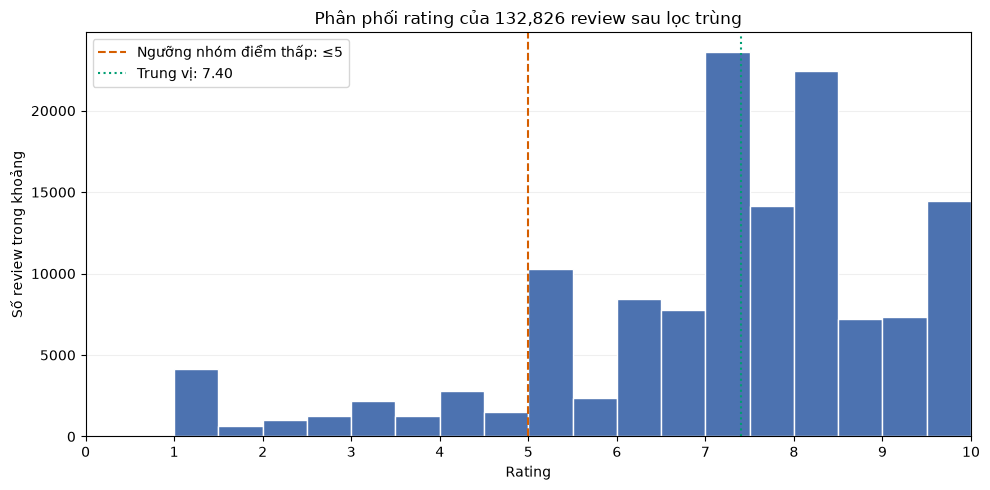

In [10]:
rating = corpus["rating_num"].dropna()

if rating.empty:
    raise ValueError("Không có rating để vẽ.")

n_low = int(rating.le(5).sum())
n_other = int(rating.gt(5).sum())

print(f"Tổng review: {len(rating):,}")
print(f"Rating ≤5, gồm cả 0: {n_low:,} ({n_low / len(rating):.2%})")
print(f"Rating >5: {n_other:,} ({n_other / len(rating):.2%})")

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    rating,
    bins=np.linspace(0, 10, 21),
    color="#4C72B0",
    edgecolor="white",
)

ax.axvline(
    5,
    color="#D55E00",
    linestyle="--",
    label="Ngưỡng nhóm điểm thấp: ≤5",
)

ax.axvline(
    rating.median(),
    color="#009E73",
    linestyle=":",
    label=f"Trung vị: {rating.median():.2f}",
)

ax.set(
    title=f"Phân phối rating của {len(rating):,} review sau lọc trùng",
    xlabel="Rating",
    ylabel="Số review trong khoảng",
    xlim=(0, 10),
    xticks=range(11),
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 4.Phân phối n_tokens — xem độ dài trải rộng thế nào
Bảng thống kê trước đó chỉ cho vài mốc như trung vị, P95 và lớn nhất. Histogram giúp nhìn rõ:
- Phần lớn comment tập trung trong khoảng độ dài nào?
- Comment dài có hiếm không?
- Phân phối có đuôi dài không?

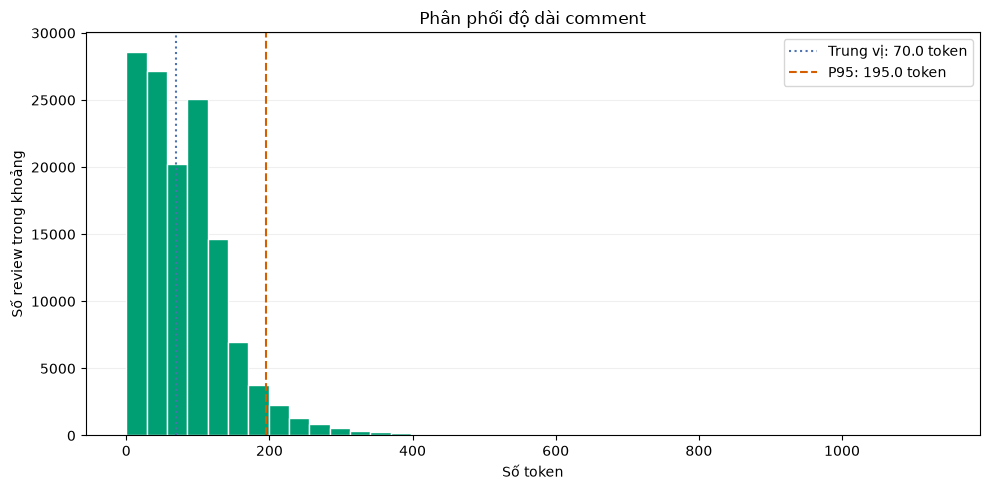

In [11]:
lengths = corpus["n_tokens"].dropna()

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    lengths,
    bins=40,
    color="#009E73",
    edgecolor="white",
)

ax.axvline(
    lengths.median(),
    color="#4C72B0",
    linestyle=":",
    label=f"Trung vị: {lengths.median():.1f} token",
)

ax.axvline(
    lengths.quantile(0.95),
    color="#D55E00",
    linestyle="--",
    label=f"P95: {lengths.quantile(0.95):.1f} token",
)

ax.set(
    title="Phân phối độ dài comment",
    xlabel="Số token",
    ylabel="Số review trong khoảng",
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

Độ dài comment chênh lệch lớn khiến nhóm comment ngắn bị dồn sát bên trái trên thang thường. Chuyển trục X sang thang logarit giúp nhìn rõ phân bố nhóm này mà vẫn thể hiện được các comment rất dài.

Tổng review được đo: 132,826
Review có token: 132,680
Review 0 token, không vẽ trên trục log: 146


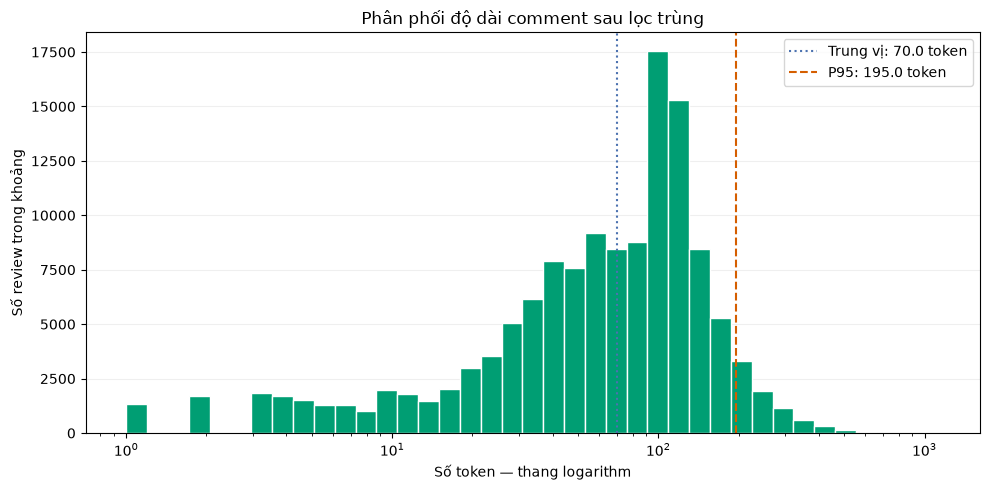

In [12]:
# n_tokens đã được tính ở bước đo khối lượng văn bản.
lengths = corpus["n_tokens"].dropna()
positive_lengths = lengths.loc[lengths.gt(0)]

n_zero = int(lengths.eq(0).sum())

print(f"Tổng review được đo: {len(lengths):,}")
print(f"Review có token: {len(positive_lengths):,}")
print(f"Review 0 token, không vẽ trên trục log: {n_zero:,}")

if positive_lengths.empty:
    raise ValueError("Không có comment có token để vẽ.")

median_length = positive_lengths.median()
p95_length = positive_lengths.quantile(0.95)

# Chia khoảng theo thang logarithm để thể hiện cả phần ngắn và dài.
length_bins = np.geomspace(
    1,
    positive_lengths.max() + 1,
    40,
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    positive_lengths,
    bins=length_bins,
    color="#009E73",
    edgecolor="white",
)

ax.set_xscale("log")

ax.axvline(
    median_length,
    color="#4C72B0",
    linestyle=":",
    label=f"Trung vị: {median_length:.1f} token",
)

ax.axvline(
    p95_length,
    color="#D55E00",
    linestyle="--",
    label=f"P95: {p95_length:.1f} token",
)

ax.set(
    title="Phân phối độ dài comment sau lọc trùng",
    xlabel="Số token — thang logarithm",
    ylabel="Số review trong khoảng",
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

- Trung vị là 70 token: khoảng một nửa comment dài không quá 70 token. Đây là mốc mô tả độ dài điển hình.
- P95 là 195 token: khoảng 95% comment có token dài không quá 195 token; chỉ khoảng 5% vượt mốc này.

### 4. Khảo sát nội dung lặp còn lại sau lọc trùng

Ta gom các review có cùng `text_norm` để thống kê:
- Có bao nhiêu review cùng nội dung?
- Chúng xuất hiện tại bao nhiêu quán?
- Chúng có cùng rating hay xuất hiện ở nhiều mức điểm?
- Có bao nhiêu review thuộc nhóm rating ≤5?

Mục đích là hiểu mức tập trung và sự đa dạng của bằng chứng trước khi
phân tích keyword. Một cụm xuất hiện trong nhiều review có thể đến từ
nhiều câu khác nhau hoặc chủ yếu từ một câu được lặp lại.

Cùng nội dung nhưng khác quán vẫn có thể phản ánh những trải nghiệm
khác nhau. Vì vậy, bước này chỉ khảo sát, không kết luận nội dung lặp
là spam và không xóa thêm review.

Dữ liệu sử dụng là `corpus`: tập review hợp lệ sau lọc trùng,
gồm cả nhóm rating ≤5 và >5.

In [13]:
# Chọn tất cả dòng thuộc nhóm có text_norm xuất hiện nhiều lần.
# keep=False đánh dấu cả dòng đầu và những dòng xuất hiện sau.
repeated_mask = corpus["text_norm"].duplicated(keep=False)
repeated_reviews = corpus.loc[repeated_mask].copy()

# Tạo cột phụ trên bản sao để đếm nhóm điểm thấp.
repeated_reviews["is_low"] = repeated_reviews["rating_num"].le(5)

duplicate_groups = (
    repeated_reviews
    .groupby("text_norm")
    .agg(
        so_review=("rating_num", "size"),
        so_quan=("shop_id", "nunique"),
        so_muc_rating=("rating_num", "nunique"),
        rating_min=("rating_num", "min"),
        rating_max=("rating_num", "max"),
        so_review_thap=("is_low", "sum"),
    )
    .sort_values("so_review", ascending=False)
    .reset_index()
)

n_repeated = len(repeated_reviews)
pct_repeated = n_repeated / len(corpus) * 100 if len(corpus) else 0

print(f"Tổng review sau lọc: {len(corpus):,}")
print(f"Số nội dung khác nhau: {corpus['text_norm'].nunique():,}")
print(f"Số nhóm nội dung lặp: {len(duplicate_groups):,}")
print(f"Review thuộc các nhóm lặp: {n_repeated:,} ({pct_repeated:.2f}%)")

# Chỉ giới hạn cách hiển thị; không cắt nội dung trong dữ liệu.
with pd.option_context(
    "display.max_colwidth", 180,
    "display.max_columns", None,
):
    display(
        duplicate_groups.head(25).rename(columns={
            "text_norm": "Nội dung chuẩn hóa",
            "so_review": "Số review",
            "so_quan": "Số quán",
            "so_muc_rating": "Số mức rating",
            "rating_min": "Rating thấp nhất",
            "rating_max": "Rating cao nhất",
            "so_review_thap": "Số review ≤5",
        })
    )

Tổng review sau lọc: 132,826


Số nội dung khác nhau: 126,236
Số nhóm nội dung lặp: 1,258
Review thuộc các nhóm lặp: 7,848 (5.91%)


,Nội dung chuẩn hóa,Số review,Số quán,Số mức rating,Rating thấp nhất,Rating cao nhất,Số review ≤5
0,ngon,482,134,22,5.0,10.0,137
1,nem nướng ngon,395,3,6,5.0,10.0,14
2,tốt,280,35,20,3.0,10.0,198
3,rất ngon,232,58,17,5.0,10.0,65
4,tuyệt vời,171,71,19,5.0,10.0,71
5,10 điểm cho chất lượng,166,8,11,5.0,10.0,112
6,vừa miệng,151,1,12,5.0,10.0,110
7,ngon tuyệt,125,34,15,5.0,10.0,49
8,dịch vụ tốt,122,24,12,5.0,10.0,85
9,"bánh ngon, mềm và thơm nứt mũi luôn ạ ☺️☺️☺️",98,1,1,10.0,10.0,0


#### Đánh giá nội dung lặp sau lọc trùng

- Nội dung giống nhau vẫn xuất hiện ở nhiều quán. Chẳng hạn, “ngon”
  xuất hiện trong 602 review tại 134 quán. Đây có thể là cách diễn đạt
  phổ biến của nhiều người, nên không loại thêm chỉ vì trùng text.

- Một số nội dung lặp nhiều nhưng tập trung tại ít quán cần được kiểm tra
  thêm về người viết, thời điểm và dữ liệu nguồn. Chỉ riêng số lần lặp
  chưa đủ để kết luận spam hoặc lỗi thu thập.

- Cùng một nội dung có thể đi kèm nhiều mức rating. Vì vậy, câu chữ
  không luôn tương ứng với một mức điểm; khi tìm keyword cần so sánh
  tỷ lệ giữa nhóm ≤5 và >5, đồng thời đọc ngữ cảnh.

- Rating nhỏ nhất và lớn nhất chỉ cho biết khoảng điểm của nhóm cùng
  nội dung, chưa chứng minh rating phân bố đều hoặc phản ánh phân phối
  rating của riêng một quán.

**Hệ quả cho phân tích tiếp theo:** giữ các review sau lọc hiện tại.
Khi đánh giá keyword, xem thêm số nội dung khác nhau và số quán đóng góp,
để biết kết quả có bị tập trung vào một vài câu lặp hoặc một vài quán không.

Bảng hiển thị 25 nội dung lặp nhiều nhất, không đại diện cho toàn bộ
bình luận và chưa phải bảng kết quả keyword.

### 5. Đọc mẫu để đối chiếu thống kê với nội dung thực tế

Khảo sát trên `corpus` — dữ liệu hợp lệ sau lọc trùng — theo hai cách:

1. Đọc các trường hợp đặc biệt:
   - Rating 0: quan sát nội dung và ghi nhận khả năng điểm không khớp cảm xúc.
   - Comment 0 token: kiểm tra những nội dung regex không nhận diện.
   - Comment dài nhất: xem đó là đánh giá chi tiết hay nội dung bất thường.

2. Lấy mẫu ngẫu nhiên trong hai nhóm rating ≤5 và >5:
   quan sát cách diễn đạt, chủ đề và nội dung khen/chê có thể xuất hiện
   trong mỗi nhóm. Nhóm ≤5 vẫn bao gồm rating 0.

Mục đích là phát hiện vấn đề và đặt giả thuyết cần kiểm tra tiếp,
không gán nhãn cảm xúc cho toàn dataset hoặc tự động sửa rating.

Các mẫu đặc biệt không đại diện toàn bộ dữ liệu. Mẫu ngẫu nhiên nhỏ
chỉ giúp quan sát ban đầu, chưa đủ để ước lượng tỷ lệ hay kết luận
đặc trưng của mỗi nhóm. Một review có thể xuất hiện ở nhiều bảng mẫu.

In [14]:
SEED = 42
N_SAMPLE = 5

def show_review_sample(rows, title, n=N_SAMPLE, random_sample=True):
    print(f"\n{title}")
    print(f"Số review trong nhóm: {len(rows):,}")

    if rows.empty:
        print("Không có review thuộc nhóm này.")
        return

    # Nhóm nhỏ hơn n thì hiển thị toàn bộ.
    sample_size = min(n, len(rows))

    if random_sample:
        selected = rows.sample(n=sample_size, random_state=SEED)
    else:
        selected = rows.head(sample_size)

    columns = [
        "review_id",
        "shop_id",
        "rating_num",
        "n_tokens",
        "comment_text",
    ]

    # Hiển thị toàn bộ comment gốc để đọc ngữ cảnh.
    with pd.option_context(
        "display.max_colwidth", None,
        "display.max_columns", None,
    ):
        display(selected[columns])


# 1. Các trường hợp đặc biệt
show_review_sample(
    corpus.loc[corpus["rating_num"].eq(0)],
    "A. Mẫu review rating = 0",
)

show_review_sample(
    corpus.loc[corpus["n_tokens"].eq(0)],
    "B. Mẫu comment không có token theo regex",
)

show_review_sample(
    corpus.nlargest(3, "n_tokens"),
    "C. Ba comment dài nhất",
    n=3,
    random_sample=False,
)


# 2. Mẫu ngẫu nhiên trong từng nhóm rating
show_review_sample(
    corpus.loc[corpus["rating_num"].le(5)],
    "D. Mẫu ngẫu nhiên nhóm rating ≤5 — gồm cả rating 0",
)

show_review_sample(
    corpus.loc[corpus["rating_num"].gt(5)],
    "E. Mẫu ngẫu nhiên nhóm rating >5",
)


A. Mẫu review rating = 0
Số review trong nhóm: 40


,review_id,shop_id,rating_num,n_tokens,comment_text
67204,67205,the-alley-tra-sua-dai-loan-nguyen-van-cu,0.0,43,"Trân châu ấm mềm ngọt nhẹ nhàng, sữa thơm béo nhẹ cùng vị cacao hoà quyện đậm đà. \nSau món sữa tươi trân châu đường là best của The Alley thì cũng nên thử qua món này nha, ngon số dazch luôn đó."
42753,42754,rau-ma-sinh-to-lap-thanh,0.0,6,Trương trình món ngon mỗi ngày
41595,41596,que-nha-quan-com-nieu,0.0,10,Quán chuyển sang. 158 Lê Hồng Phong . Các bạn nha
87396,87397,tien-hai-quan-bun-dau-mam-tom,0.0,111,"Quán là chi nhánh thứ 2 sau quấn gốc ở đường Nguyễn Tri Phương vì quá đông.\nquán nằm trên đường sư vạn hạnh cũng dễ tìm vì nằm ngòai mặt tiền. Do vỉa hè của quán nhỏ nên nếu ko còn chổ thì phải gửi xe gần đó rồi đi bộ lại.\nMình đã ăn ở đây rất nhiều lần, tuy chi nhánh khác nhưng hương vị ko thay đổi.\nQuán bên chi nhánh này có cải tiến bếp để bên trong nhà, và thoáng hơn.\nCó nhiều loại bún đậu để khách gọi từ 35k đến 55k.\nQuán tuy đông nhưng nhân viên nhiệt tình. lên món hơi lâu."
7811,7812,banh-cong-co-ut-ly-tu-trong,0.0,106,"QUá nổi tiếng chỉ có một món bánh cống thôi mà luôn luôn khách đông vào rần rần, thường có cả gia đình lớn đi ăn.\nVị trí cũng quen thuộc nhiều người đã biết đi xe hơi vào cũng oki được hết luôn. Có chỗ để xe máy trong nhà. \nKhông gian ổn.\nBánh cống cái bành với lớp vỏ giòn giờn tan luôn con tôm ngon mắt trên mặt lớp nhân mềm thơm bùi bùi với đậu xanh thịt ăn hài hoà vô cùng thêm chút rau xanh ăn kèm nước mắm chua ngọt không thể cưỡng lại được :) :) :) hihi 11k / 1 cái nhe"



B. Mẫu comment không có token theo regex
Số review trong nhóm: 146


,review_id,shop_id,rating_num,n_tokens,comment_text
20981,20982,%E8%8C%B6%E9%A4%90%E5%8E%85-cha-chaan-teng-am-thuc-hongkong,10.0,0,👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼👍🏼
66299,66300,banh-cuon-nong-41,10.0,0,😍😍😍😍😍😍😍😍😍
13211,13212,lotteria-vincom-xuan-khanh,10.0,0,😘😘
7400,7401,crystal-jade-kitchen-vincom-xuan-khanh,8.6,0,🤩
20972,20973,%E8%8C%B6%E9%A4%90%E5%8E%85-cha-chaan-teng-am-thuc-hongkong,6.0,0,👍🏻👍🏻👍🏻👍🏻👍🏻👍🏻👍🏻👍🏻👍🏻



C. Ba comment dài nhất
Số review trong nhóm: 3


review_id                           shop_id  rating_num  n_tokens  \
25846      25847  hanuri-quan-an-han-quoc-cong-hoa        10.0      1136   
48169      48170        banh-canh-hem-pham-van-chi         7.4      1105   
68613      68614             phong-cua-cay-su-quan         2.0      1098   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                      


D. Mẫu ngẫu nhiên nhóm rating ≤5 — gồm cả rating 0
Số review trong nhóm: 23,206


,review_id,shop_id,rating_num,n_tokens,comment_text
70343,70344,com-nieu-thien-ly-hoang-hoa-tham,5.0,10,"Cơm dẻo, thơm đặc biệt thức ăn rất vừa miệng"
119286,223531,mi-cay-redsun-200d-to-hieu,5.0,12,Mình gọi cấp 4 mà ship đến không cay tí nào .chán
86985,86986,highlands-coffee-tra-ca-phe-banh-cach-mang-thang-8,3.6,173,"Ghé quán chưa được 30ph. Ra lấy xe đi về đi được giữa đường phát hiện gô cơm và áo mưa mất tích... trong khi mũ bảo hiểm vẫn còn. Trước khi vào anh bảo vệ có nhắc nhở có mang mấy thứ này vào không( mấy thứ này bao gồm áo mưa và gô cơm chưa rửa...)...mình bảo ko, ai đâu lấy gô cơm giở đi làm. 😂\nLỗi do mình ko bỏ cốp, vì nghĩ rằng ko ai đi lấy trộm gô cơm của phụ nữ mang đi làm cả, áo mưa 40k/ cái đầy lề đường trong khi cái nón Sơn 400k/cái không lấy. Cạn lời. Không dám trách ai nhưng cũng muốn nhắc mọi người dù ít dù nhiều của mình thì cứ bỏ cốp cho thiên hạ đỡ ngứa mắt, mất cũng phải mua lại--> mí trăm ngàn đâu có ít. Haiz anyway đang tiếc của với bực bậu... đã đc nhắc nhở...😂 Mà vẫn để mất.... để ở đây, ai ném đá mình nhận hết haiz...."
82508,82509,sui-cao-thien-thien-ha-ton-quyen,4.0,50,"Chả có gì đặc sắc cả, 1 tô thập cẩm có vài cục sửu cảo nhỏ xíu :v thêm mấy cái topping đi kèm ăn vào chẳng khác gì ăn cao su, miếng mực y chang, màu thì sậm nhu màu mũ, ăn vào k có cảm giác đc gì"
100430,100431,louisiane-brewhouse-tran-phu,5.0,18,"Nha trang,quán này là một trong quán độc đáo nhất định phải tới thử 1 lần nhé"



E. Mẫu ngẫu nhiên nhóm rating >5
Số review trong nhóm: 109,620


,review_id,shop_id,rating_num,n_tokens,comment_text
90277,90278,burgers-min-min,7.2,11,Thích khoai tây thẻ và cà phê dừa ở đây nhất 😍🍟🍟🍔
28638,28639,sup-cua-bong-mac-dinh-chi,9.6,40,Trời lạnh lạnh nên nhiều ng cứ gth ăn súp cua của quán. Nay đặt thử súp cua đặc biệt xem tn. Bát súp ngon hết sảy luôn. Đồ uống của quán cũng ngon ý. Mình sẽ đặt thường xuyên
119537,223782,starbucks-coffee-tran-phu,8.0,389,"#review #Starbucks15atranphu\n#gócthửđộc #đồmùa \n#MilkTeaPannaCottaFrappuccino #PistachioBonBonFrappuccino\n____________________\nHóng trên page thấy ra mắt đồ mới lâu r mà con bé mãi mới sắp xếp được thời gian qua Bà Đầm thử độc😉😉Bước vào thấy các anh chị nhân viên nhiệt tình chào đón, lại còn giới thiệu chương trình mua đồ mùa mới tặng túi nữa nên e hào hứng lắm tham gia luôn 😍😍😍\n\nE chọn 2 đồ mới size lớn ( ít đường ) hết 111k ( vì thẻ e đang có km mua 1 tặng 1 ) - bill dấu đỏ vẫn được áp dụng #mua1tặng1 vào các buổi chiều hàng tuần đến hết #28_6 nha mọi người\n\n2 cốc to chà bá, deco khá bắt mắt cơ mà vị thì e thấy hơi xuống phong độ so với đồ mùa hè trước đó, nhìn chung không đặc sắc mấy\n\n#MilkTeaPannaCottaFrappuccino (e gọi nôm la là trà sữa 😂😂😂): là 1 lớp đá xay như kiểu choco hay đại loại thế, lớp dưới là pudding trứng thì phải cơ mà tất cả làm chưa có tới😞😞Là trà sữa mà vị trà k có mấy, sữa cũng khá là ít, chưa kể cái phudding trứng ăn như tào phớ 😂😂😂😂. Chắc cứu vớt cả cốc được lớp kem whip bên trên và ít ngọt đúng ý của em😂😂😂 là fan trà sữa chính hiệu nên cốc này e k đánh giá cao lắm chỉ dùng lại ở mức độ tạm ổn và không gây thương nhớ như các đồ mùa trước 😔😔😔😔\n\n#PistachioBonBonFrappuccino (em gọi nôm na là matcha đậu nành😉😉)Vì sao ư??? Cốc này là sự hòa quyện của matcha đá xay,đậu nành và chocolate ( siro choco bôi xung quanh cốc ) Bao trum cả cốc là vị đậu nành được đẩy lên cực rõ😉😉😉😉chưa kể lớp kem whip bên trên được cho thêm siro chocolate và vụn đậu nành ( nếu e nhớ không lầm). Cốc này khá khẩm hơn sơ với milk tea cơ mà vị matcha đẩy lên chưa có rõ, thơm vị matcha chút nữa uống sẽ thích hơn nhiều 😍😍😍😍 Điểm trừ nhỏ xíu nữa là cốc này vẫn bị ngọt so với khẩu vị của em mặc dù đã dặn kỹ các ac nhân viên cho ít đường 😭😭😭😭chắc lần sau gọi không đường uống sẽ okk hơn ak\nTrong hình ảnh có thể có: đồ uống"
33229,33230,lau-ca-thac-lac-tuoi-dac-biet-phan-phu-tien.jj93kq,7.6,3,Ngon tuyệt vời
13678,13679,highlands-coffee-tra-ca-phe-banh-vincom-can-tho,8.4,120,"Cũng đã thử qua các món Freeze trà xanh, Caramel phin freeze, Freeze socola, Cookies & cream\nthì chỉ thấy trà xanh với caramel là uống ngon nhất. Còn dở nhất chắc là Cookies & cream vì với giá đó thì nói thiệt là đi quán khác uống sẽ ngon hơn nhiều, cái vị nó cứ là lạ sao ý, nó không quá ngon như kỳ vọng. Còn freeze trà xanh thì khỏi bàn rồi, món tủ mà lị. Về không gian quán thì vẫn yên tĩnh vì cũng vắng người và quán cũng sạch sẽ thoáng mát tuy là máy lạnh hơi yếu (nói chứ cũng đông nhưng không đến nổi nghẹt người như bên sense và cũng dễ thở hơn)"


Với nhóm comment > 5 và <= 5 nhưng khác 0 , comment đa số phản ánh đúng với rating . Tuy nhiên với rating = 0 thì toàn các cmt tích cực , gây loãng rating . Với comment 0 token thì chỉ toàn icon , không mang nhiều ý nghĩa . 
--> Quyết định bỏ đi rating = 0 và comment 0 token 

### 6. Tạo tập làm việc cho phân tích n-gram

Tạo `working` từ `corpus`, loại các review:
- Rating = 0: qua mẫu đã đọc, nhiều comment có nội dung tích cực,
  nên không tiếp tục xếp nhóm này vào nhóm điểm thấp.
- Có 0 token: không tạo được đặc trưng theo regex hiện tại.
  Điều này không đồng nghĩa emoji không mang ý nghĩa.

Báo cáo số dòng thuộc từng điều kiện, phần giao nhau và tổng số dòng
bị loại. Không cộng trực tiếp hai số đếm vì một review có thể vừa
rating 0 vừa có 0 token.

Trong `working`, tạo nhãn `is_low`:
- True: 0 < rating ≤5.
- False: rating >5.

Mục đích là xác định rõ dữ liệu và nhóm điểm dùng cho các phép đếm tiếp
theo. Tính lại tỷ lệ nhóm điểm thấp sau lọc; tỷ lệ này là mốc tham khảo
để đánh giá liên hệ giữa keyword và điểm thấp.

Không sửa rating hoặc xóa dòng khỏi dữ liệu gốc.

In [15]:
zero_rating = corpus["rating_num"].eq(0)
zero_tokens = corpus["n_tokens"].eq(0)

remove_mask = zero_rating | zero_tokens

removal_report = pd.DataFrame([
    {"Hạng mục": "Review trước bước lọc này", "Số review": len(corpus)},
    {"Hạng mục": "Có rating = 0", "Số review": int(zero_rating.sum())},
    {"Hạng mục": "Có 0 token", "Số review": int(zero_tokens.sum())},
    {
        "Hạng mục": "Đồng thời rating = 0 và 0 token",
        "Số review": int((zero_rating & zero_tokens).sum()),
    },
    {"Hạng mục": "Tổng review bị loại", "Số review": int(remove_mask.sum())},
    {"Hạng mục": "Review còn lại", "Số review": int((~remove_mask).sum())},
])

display(removal_report)

working = corpus.loc[~remove_mask].copy()

if working.empty:
    raise ValueError("Không còn review để phân tích.")

working["is_low"] = working["rating_num"].le(5)

group_summary = pd.DataFrame({
    "Nhóm": ["0 < rating ≤5", "Rating >5"],
    "Số review": [
        int(working["is_low"].sum()),
        int((~working["is_low"]).sum()),
    ],
})
group_summary["Tỷ lệ (%)"] = (
    group_summary["Số review"] / len(working) * 100
).round(2)

display(group_summary)
print(f"Tỷ lệ điểm thấp trong working: {working['is_low'].mean():.2%}")

,Hạng mục,Số review
0,Review trước bước lọc này,132826
1,Có rating = 0,40
2,Có 0 token,146
3,Đồng thời rating = 0 và 0 token,0
4,Tổng review bị loại,186
5,Review còn lại,132640


,Nhóm,Số review,Tỷ lệ (%)
0,0 < rating ≤5,23144,17.45
1,Rating >5,109496,82.55


Tỷ lệ điểm thấp trong working: 17.45%


### 7. Tạo nhiều lần chia để kiểm tra độ ổn định

Một lần chia có thể khiến keyword ít mẫu phân bố lệch giữa discovery
và validation. Vì vậy, thực hiện 5 lần chia với seed cố định:

- Discovery: tìm keyword ứng viên.
- Validation: đo lại liên hệ giữa keyword và nhóm điểm thấp.

Mỗi lần chia dành khoảng 20% nhóm `text_norm` cho validation.
Các review cùng nội dung chuẩn hóa luôn nằm cùng phía trong một lần
chia, tránh kiểm chứng lại bằng nguyên câu đã dùng để khám phá.

Tỷ lệ 20% áp dụng cho nhóm nội dung, không bảo đảm đúng 20% số review.
Báo cáo tỷ lệ điểm thấp của từng tập để theo dõi mức chênh lệch.
Mọi phép tính lift sử dụng tỷ lệ nền riêng của tập tương ứng.

Mục đích là xem kết quả có phụ thuộc nhiều vào một lần chia hay không.
Không chọn riêng lần chia cho kết quả đẹp nhất.

Các lần chia có thể sử dụng lại review nên kết quả giữa chúng không
độc lập. Đây là kiểm tra độ ổn định khi chia dữ liệu, chưa chứng minh
khả năng áp dụng sang quán mới hoặc thời điểm mới.

In [16]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

SEED = 42
N_SPLITS = 5
VALIDATION_SIZE = 0.20

splitter = GroupShuffleSplit(
    n_splits=N_SPLITS,
    test_size=VALIDATION_SIZE,
    random_state=SEED,
)

# Chỉ lưu vị trí dòng để tránh sao chép toàn bộ dữ liệu nhiều lần.
split_indices = []
split_reports = []

for split_id, (disc_pos, val_pos) in enumerate(
    splitter.split(working, groups=working["text_norm"]),
    start=1,
):
    discovery_part = working.iloc[disc_pos]
    validation_part = working.iloc[val_pos]

    overlap = (
        set(discovery_part["text_norm"])
        & set(validation_part["text_norm"])
    )
    assert not overlap

    if any(
        part["is_low"].nunique() < 2
        for part in [discovery_part, validation_part]
    ):
        raise ValueError(
            f"Lần chia {split_id} có tập thiếu một nhóm rating."
        )

    split_indices.append((split_id, disc_pos, val_pos))

    for name, part in [
        ("Discovery", discovery_part),
        ("Validation", validation_part),
    ]:
        split_reports.append({
            "Lần chia": split_id,
            "Tập": name,
            "Số review": len(part),
            "Số text khác nhau": part["text_norm"].nunique(),
            "Review điểm thấp": int(part["is_low"].sum()),
            "Tỷ lệ điểm thấp (%)": round(
                part["is_low"].mean() * 100, 2
            ),
        })

display(pd.DataFrame(split_reports))

,Lần chia,Tập,Số review,Số text khác nhau,Review điểm thấp,Tỷ lệ điểm thấp (%)
0,1,Discovery,106154,100897,18537,17.46
1,1,Validation,26486,25225,4607,17.39
2,2,Discovery,106130,100897,18647,17.57
3,2,Validation,26510,25225,4497,16.96
4,3,Discovery,105801,100897,18439,17.43
5,3,Validation,26839,25225,4705,17.53
6,4,Discovery,106256,100897,18666,17.57
7,4,Validation,26384,25225,4478,16.97
8,5,Discovery,105708,100897,18404,17.41
9,5,Validation,26932,25225,4740,17.60


### 8. Tìm ứng viên và kiểm tra độ ổn định qua nhiều lần chia

Thực hiện riêng trong mỗi lần chia:

1. Tạo từ điển n-gram 1–3 từ discovery, chỉ dùng review điểm thấp.
2. Giữ cụm xuất hiện trong ít nhất 5 review điểm thấp.
3. Đếm cụm trên cả hai nhóm rating của discovery.
4. Chọn ứng viên có lift ≥2 trên discovery.
5. Đếm và tính lại lift trên validation bằng từ điển vừa tìm được.

Mỗi cụm chỉ được tính tối đa một lần trong mỗi review.

Lift = tỷ lệ review điểm thấp trong những review chứa cụm
       / tỷ lệ review điểm thấp của tập đang xét.

- Lift ≥2: tỷ lệ điểm thấp khi có cụm ít nhất gấp đôi mức nền.
- Lift =1: bằng mức nền.
- Lift <1: thấp hơn mức nền.

Một lần kiểm chứng chỉ được đưa vào tổng hợp lift nếu validation có
ít nhất 10 review chứa cụm. Nếu ít hơn, ghi nhận thiếu bằng chứng;
không coi keyword đó là thất bại hoặc gán lift bằng 0.

Tổng hợp cho từng keyword:
- Số lần được chọn trên discovery.
- Số lần validation có đủ mẫu.
- Tỷ lệ lần đủ mẫu có lift validation ≥2.
- Trung vị, nhỏ nhất và lớn nhất của lift validation ở các lần đủ mẫu.

Quy ước khảo sát ban đầu cho nhãn “ổn định”:
- Được chọn trong ít nhất 4/5 lần chia.
- Có ít nhất 3 lần kiểm chứng đủ mẫu.
- Ít nhất 80% lần kiểm chứng đủ mẫu có lift ≥2.

Ngưỡng lift ≥2 áp dụng cho cả chọn trên discovery và đánh giá trên validation.
Các ngưỡng này là tiêu chí làm việc, không phải bảo đảm thống kê.
Khoảng lift nhỏ nhất–lớn nhất không phải khoảng tin cậy.
Các keyword có dưới 3 lần kiểm chứng đủ mẫu được ghi là chưa đủ
bằng chứng để đánh giá độ ổn định.

Kết quả dùng `keyword_runs` và `keyword_stability` thay cho bảng
`stats` của một lần chia trước đó. Chưa kết luận keyword tiêu cực
nếu chưa đọc ngữ cảnh.

In [17]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

TOKEN_PATTERN = r"(?u)\b\w+\b"
MIN_LOW_SUPPORT = 5
MIN_LIFT = 2.0
MIN_VALID_SUPPORT = 10
BATCH_SIZE = 5000

MIN_SELECTED_SPLITS = 4
MIN_EVALUABLE_SPLITS = 3
MIN_POSITIVE_RATE = 0.80


def count_support(vectorizer, texts):
    """Đếm số review chứa từng cụm, xử lý theo lô."""
    counts = np.zeros(
        len(vectorizer.get_feature_names_out()),
        dtype=np.int64,
    )

    for start in range(0, len(texts), BATCH_SIZE):
        matrix = vectorizer.transform(
            texts.iloc[start:start + BATCH_SIZE]
        )
        counts += np.asarray(matrix.sum(axis=0)).ravel()
        del matrix

    return counts


run_tables = []
candidate_reports = []

for split_id, disc_pos, val_pos in split_indices:
    disc = working.iloc[disc_pos]
    val = working.iloc[val_pos]

    baseline_disc = float(disc["is_low"].mean())
    baseline_val = float(val["is_low"].mean())

    vectorizer = CountVectorizer(
        token_pattern=TOKEN_PATTERN,
        ngram_range=(1, 3),
        lowercase=False,
        binary=True,
        min_df=MIN_LOW_SUPPORT,
        dtype=np.int32,
    )

    # Tìm ứng viên riêng từ discovery của lần chia hiện tại.
    low_matrix = vectorizer.fit_transform(
        disc.loc[disc["is_low"], "text_norm"]
    )
    low_disc = np.asarray(low_matrix.sum(axis=0)).ravel()
    del low_matrix

    keywords = vectorizer.get_feature_names_out()
    support_disc = count_support(vectorizer, disc["text_norm"])

    lift_disc = (low_disc / support_disc) / baseline_disc

    # Chọn chỉ bằng discovery, chưa nhìn kết quả validation.
    selected = lift_disc >= MIN_LIFT

    candidate_reports.append({
        "Lần chia": split_id,
        "Ứng viên đạt support": len(keywords),
        "Ứng viên có lift discovery ≥2": int(selected.sum()),
    })

    if not selected.any():
        continue

    support_val = count_support(vectorizer, val["text_norm"])
    low_val = count_support(
        vectorizer,
        val.loc[val["is_low"], "text_norm"],
    )

    # Không có review chứa cụm => lift chưa xác định, giữ NaN.
    p_low_val = np.divide(
        low_val,
        support_val,
        out=np.full(len(keywords), np.nan),
        where=support_val > 0,
    )
    lift_val = p_low_val / baseline_val

    run = pd.DataFrame({
        "split": split_id,
        "keyword": keywords[selected],
        "support_discovery": support_disc[selected],
        "low_support_discovery": low_disc[selected],
        "lift_discovery": lift_disc[selected],
        "support_validation": support_val[selected],
        "low_support_validation": low_val[selected],
        "lift_validation": lift_val[selected],
    })

    run["evaluable"] = (
        run["support_validation"] >= MIN_VALID_SUPPORT
    )
    run["positive_validation"] = run["lift_validation"] >= MIN_LIFT

    run_tables.append(run)

    print(
        f"Lần {split_id}: chọn {len(run):,} cụm; "
        f"{run['evaluable'].sum():,} cụm đủ mẫu kiểm chứng."
    )

display(pd.DataFrame(candidate_reports))

if not run_tables:
    raise ValueError("Không có ứng viên đạt điều kiện discovery.")

keyword_runs = pd.concat(run_tables, ignore_index=True)

# Số lần keyword được chọn trên discovery.
selection_summary = keyword_runs.groupby("keyword").agg(
    n_selected=("split", "nunique"),
    median_discovery_lift=("lift_discovery", "median"),
)

# Chỉ tổng hợp lift validation ở những lần có đủ mẫu.
validation_summary = (
    keyword_runs.loc[keyword_runs["evaluable"]]
    .groupby("keyword")
    .agg(
        n_evaluable=("split", "nunique"),
        positive_rate=("positive_validation", "mean"),
        median_validation_lift=("lift_validation", "median"),
        min_validation_lift=("lift_validation", "min"),
        max_validation_lift=("lift_validation", "max"),
    )
)

keyword_stability = (
    selection_summary
    .join(validation_summary, how="left")
    .reset_index()
)

keyword_stability["n_evaluable"] = (
    keyword_stability["n_evaluable"].fillna(0).astype(int)
)

keyword_stability["stable"] = (
    keyword_stability["n_selected"].ge(MIN_SELECTED_SPLITS)
    & keyword_stability["n_evaluable"].ge(MIN_EVALUABLE_SPLITS)
    & keyword_stability["positive_rate"].ge(MIN_POSITIVE_RATE)
)

keyword_stability["assessment"] = np.select(
    [
        keyword_stability["n_evaluable"].lt(MIN_EVALUABLE_SPLITS),
        keyword_stability["stable"],
    ],
    [
        "Chưa đủ lần kiểm chứng",
        "Ổn định theo ngưỡng",
    ],
    default="Chưa ổn định theo ngưỡng",
)

keyword_stability = keyword_stability.sort_values(
    ["stable", "n_selected", "n_evaluable", "positive_rate"],
    ascending=False,
).reset_index(drop=True)

print("\nSố keyword theo kết quả đánh giá:")
display(
    keyword_stability["assessment"]
    .value_counts()
    .rename_axis("Đánh giá")
    .to_frame("Số keyword")
)

# Tạo bảng hiển thị; không làm tròn dữ liệu dùng để phân tích.
preview = keyword_stability.head(50).copy()
preview["positive_rate"] = preview["positive_rate"] * 100

display(
    preview.rename(columns={
        "keyword": "Cụm",
        "n_selected": "Số lần được chọn /5",
        "n_evaluable": "Số lần đủ mẫu validation",
        "positive_rate": "% lần đủ mẫu có lift ≥2",
        "median_discovery_lift": "Lift discovery trung vị",
        "median_validation_lift": "Lift validation trung vị",
        "min_validation_lift": "Lift validation nhỏ nhất",
        "max_validation_lift": "Lift validation lớn nhất",
        "stable": "Đạt tiêu chí ổn định",
        "assessment": "Đánh giá",
    }).round(3)
)

Lần 1: chọn 20,170 cụm; 3,105 cụm đủ mẫu kiểm chứng.


Lần 2: chọn 19,730 cụm; 3,100 cụm đủ mẫu kiểm chứng.


Lần 3: chọn 19,959 cụm; 3,140 cụm đủ mẫu kiểm chứng.


Lần 4: chọn 20,236 cụm; 3,082 cụm đủ mẫu kiểm chứng.


Lần 5: chọn 20,109 cụm; 3,140 cụm đủ mẫu kiểm chứng.


,Lần chia,Ứng viên đạt support,Ứng viên có lift discovery ≥2
0,1,61528,20170
1,2,61007,19730
2,3,60956,19959
3,4,61664,20236
4,5,61281,20109



Số keyword theo kết quả đánh giá:


,Số keyword
Đánh giá,
Chưa đủ lần kiểm chứng,25731
Ổn định theo ngưỡng,1834
Chưa ổn định theo ngưỡng,947


,Cụm,Số lần được chọn /5,Lift discovery trung vị,Số lần đủ mẫu validation,% lần đủ mẫu có lift ≥2,Lift validation trung vị,Lift validation nhỏ nhất,Lift validation lớn nhất,Đạt tiêu chí ổn định,Đánh giá
0,1 câu,5,3.954,5,100.0,4.040,3.896,4.454,True,Ổn định theo ngưỡng
1,1 khách,5,2.603,5,100.0,2.875,2.266,4.278,True,Ổn định theo ngưỡng
2,1 lần nào,5,4.699,5,100.0,4.735,4.517,5.471,True,Ổn định theo ngưỡng
3,1 lần và,5,3.810,5,100.0,3.628,2.599,3.980,True,Ổn định theo ngưỡng
4,1 lời,5,4.541,5,100.0,4.600,3.044,4.964,True,Ổn định theo ngưỡng
5,1 nhân,5,2.948,5,100.0,3.317,2.727,3.423,True,Ổn định theo ngưỡng
6,1 nhân viên,5,3.202,5,100.0,3.354,2.948,3.492,True,Ổn định theo ngưỡng
7,1 sao,5,5.388,5,100.0,5.134,4.419,5.749,True,Ổn định theo ngưỡng
8,1 tiếng,5,3.119,5,100.0,3.147,3.076,3.209,True,Ổn định theo ngưỡng
9,1 tiếng đồng,5,4.388,5,100.0,3.803,3.788,5.030,True,Ổn định theo ngưỡng
